In [4]:
import micropip
await micropip.install('seaborn')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

Размер: (50000, 33)
                               track_id       track_name artist_name  \
0  346d85e2-ffde-41b3-854a-589ed880b91f            Storm    Ethereal   
1  12bc268a-363b-4f19-8fa8-0ced7ae1e462           Silent   The Wolfs   
2  30d627d9-878d-4bb3-be59-71feb6ed4f3f  Shattered Lines     LolaOre   

            album_name release_date  genre  duration_ms  popularity  \
0  The Hollow Journeys   2021-10-06    Pop       169594          47   
1      Ancient Thunder   2024-10-26  K-Pop       256755          26   
2      Twisted Harbors   2022-11-12   Punk       170212          46   

   danceability  energy  ...  popularity_category  loudness_category  \
0        0.6777  0.7949  ...               Medium               Loud   
1        0.9405  0.7163  ...               Medium           Moderate   
2        0.6853  0.9500  ...               Medium               Loud   

   key_name  mode_name  is_explicit_bool  release_quarter is_weekend_release  \
0         A      Major             Fa

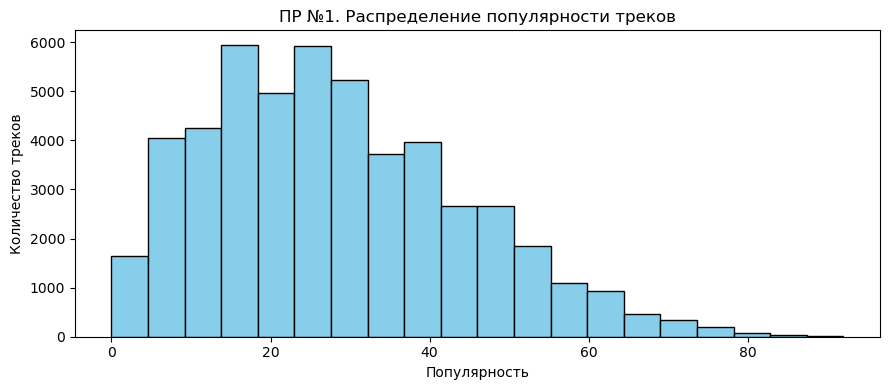

In [5]:
spotify = pd.read_csv("spotify_artist_streaming_2020_2025.csv")
print("Размер:", spotify.shape)
print(spotify.head(3))
spotify.info()

# Описательная статистика числовых признаков
print(spotify["popularity"].describe())

# Гистограмма распределения популярности
plt.figure(figsize=(9, 4))
plt.hist(spotify["popularity"], bins=20, edgecolor="black", color="skyblue")
plt.title("ПР №1. Распределение популярности треков")
plt.xlabel("Популярность")
plt.ylabel("Количество треков")
plt.tight_layout()
plt.show()

In [6]:
df = pd.read_csv("titanic.csv")
print("Строк:", df.shape[0], "| Столбцов:", df.shape[1])
print(df.columns.tolist())
print(df.dtypes)
print(df.isnull().sum())

Строк: 891 | Столбцов: 12
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [7]:
# Распределение по классам, полу, возрастным группам
print("Классы:\n", df["Pclass"].value_counts().sort_index())
print("\nПол:\n", df["Sex"].value_counts())

bins = [0, 12, 18, 30, 50, 80]
labels = ["Дети (0–12)", "Подростки (13–18)", "Молодые (19–30)",
          "Взрослые (31–50)", "Пожилые (51+)"]
df["AgeGroup"] = pd.cut(df["Age"], bins=bins, labels=labels)
print("\nВозрастные группы:\n", df["AgeGroup"].value_counts().sort_index())

print("\nСредний возраст:", round(df["Age"].mean(), 2))
print("Медианный возраст:", round(df["Age"].median(), 2))
print("Средняя стоимость билета:", round(df["Fare"].mean(), 2))

Классы:
 Pclass
1    216
2    184
3    491
Name: count, dtype: int64

Пол:
 Sex
male      577
female    314
Name: count, dtype: int64

Возрастные группы:
 AgeGroup
Дети (0–12)           69
Подростки (13–18)     70
Молодые (19–30)      270
Взрослые (31–50)     241
Пожилые (51+)         64
Name: count, dtype: int64

Средний возраст: 29.7
Медианный возраст: 28.0
Средняя стоимость билета: 32.2


In [9]:
# Средняя стоимость и возраст по классам
print(df.groupby("Pclass")["Fare"].mean().round(2))
print(df.groupby("Pclass")["Age"].mean().round(2))
print(df.groupby("Pclass")["Sex"].value_counts().unstack())

# Самый дорогой билет
top = df.loc[df["Fare"].idxmax()]
print(f"Самый дорогой билет: {top['Fare']:.2f}, класс {top['Pclass']}, "
      f"{top['Sex']}, возраст {top['Age']}, выжил: {'да' if top['Survived'] else 'нет'}")

Pclass
1    84.15
2    20.66
3    13.68
Name: Fare, dtype: float64
Pclass
1    38.23
2    29.88
3    25.14
Name: Age, dtype: float64
Sex     female  male
Pclass              
1           94   122
2           76   108
3          144   347
Самый дорогой билет: 512.33, класс 1, female, возраст 35.0, выжил: да


In [10]:
# Выживаемость по полу и классу
surv_sex = df.groupby("Sex")["Survived"].agg(["sum", "count"])
surv_sex["доля"] = surv_sex["sum"] / surv_sex["count"]
print(surv_sex)

surv_cs = df.groupby(["Pclass", "Sex"])["Survived"].agg(["sum", "count"])
surv_cs["доля"] = surv_cs["sum"] / surv_cs["count"]
print(surv_cs)
print("Лучшая группа:", surv_cs["доля"].idxmax(), "→", round(surv_cs["доля"].max()*100, 2), "%")

        sum  count      доля
Sex                         
female  233    314  0.742038
male    109    577  0.188908
               sum  count      доля
Pclass Sex                         
1      female   91     94  0.968085
       male     45    122  0.368852
2      female   70     76  0.921053
       male     17    108  0.157407
3      female   72    144  0.500000
       male     47    347  0.135447
Лучшая группа: (np.int64(1), 'female') → 96.81 %


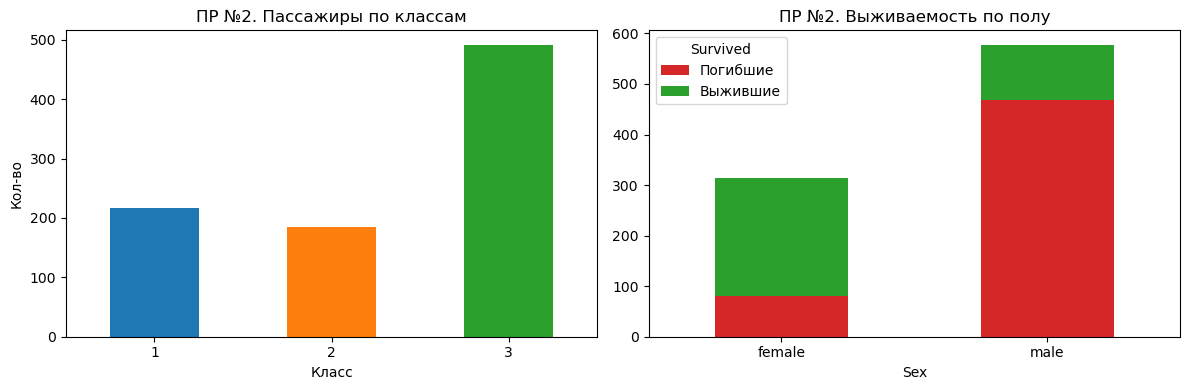

In [12]:
# Визуализация: классы и выживаемость по полу
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["Pclass"].value_counts().sort_index().plot(kind="bar", ax=ax[0],
    color=["#1f77b4", "#ff7f0e", "#2ca02c"])
ax[0].set_title("ПР №2. Пассажиры по классам")
ax[0].set_xlabel("Класс"); ax[0].set_ylabel("Кол-во"); ax[0].tick_params(rotation=0)

df.groupby(["Sex", "Survived"]).size().unstack().rename(
    columns={0: "Погибшие", 1: "Выжившие"}).plot(
    kind="bar", stacked=True, ax=ax[1], color=["#d62728", "#2ca02c"])
ax[1].set_title("ПР №2. Выживаемость по полу")
ax[1].tick_params(rotation=0)
plt.tight_layout()
plt.show()

Исходный размер: (16598, 11)
Пропуски:
 Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64
После очистки: (16327, 11)
                        Name Platform         Genre  Global_Sales
0                 Wii Sports      Wii        Sports         82.74
1          Super Mario Bros.      NES      Platform         40.24
2             Mario Kart Wii      Wii        Racing         35.82
3          Wii Sports Resort      Wii        Sports         33.00
4   Pokemon Red/Pokemon Blue       GB  Role-Playing         31.37
5                     Tetris       GB        Puzzle         30.26
6      New Super Mario Bros.       DS      Platform         30.01
7                   Wii Play      Wii          Misc         29.02
8  New Super Mario Bros. Wii      Wii      Platform         28.62
9                  Duck Hunt      NES   

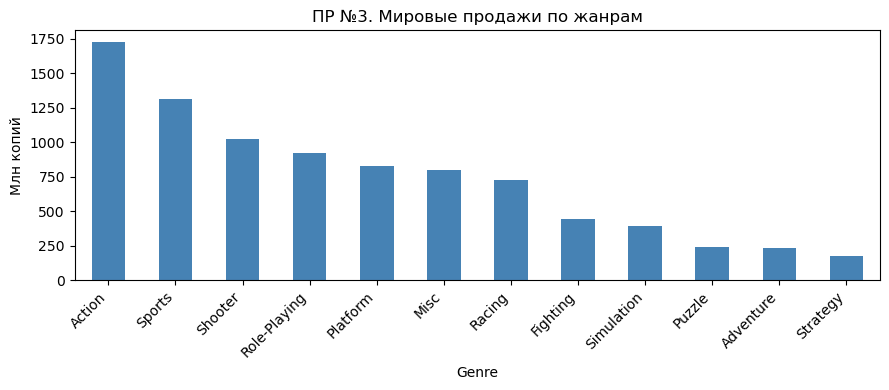

              NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales
NA_Sales          1.00      0.77      0.45         0.63          0.94
EU_Sales          0.77      1.00      0.44         0.73          0.90
JP_Sales          0.45      0.44      1.00         0.29          0.61
Other_Sales       0.63      0.73      0.29         1.00          0.75
Global_Sales      0.94      0.90      0.61         0.75          1.00


In [13]:
#  ПР №3: очистка и группировки (vgsales) 
vg = pd.read_csv("vgsales.csv")
print("Исходный размер:", vg.shape)
print("Пропуски:\n", vg.isnull().sum())

vg_clean = vg.dropna(subset=["Year"])
print("После очистки:", vg_clean.shape)

# Топ-10 игр по мировым продажам
top10 = vg_clean.nlargest(10, "Global_Sales")[["Name", "Platform", "Genre", "Global_Sales"]]
print(top10)

# Продажи по жанрам
genre_sales = vg_clean.groupby("Genre")["Global_Sales"].sum().sort_values(ascending=False)
print(genre_sales)

plt.figure(figsize=(9, 4))
genre_sales.plot(kind="bar", color="steelblue")
plt.title("ПР №3. Мировые продажи по жанрам")
plt.ylabel("Млн копий")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Корреляция региональных продаж
print(vg_clean[["NA_Sales", "EU_Sales", "JP_Sales",
                "Other_Sales", "Global_Sales"]].corr().round(2))

In [14]:
#  ПР №4: подготовка X и y 
features = ["Pclass", "Age", "Sex", "Fare", "SibSp", "Parch"]
X = df[features].copy()
y = df["Survived"]

# Пропуски в Age → медиана
X["Age"] = X["Age"].fillna(X["Age"].median())
# Кодирование Sex
X["Sex"] = X["Sex"].map({"male": 0, "female": 1})

print("Пропуски после обработки:\n", X.isnull().sum())
print("Типы:\n", X.dtypes)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)

Пропуски после обработки:
 Pclass    0
Age       0
Sex       0
Fare      0
SibSp     0
Parch     0
dtype: int64
Типы:
 Pclass      int64
Age       float64
Sex         int64
Fare      float64
SibSp       int64
Parch       int64
dtype: object
X_train: (712, 6) | X_test: (179, 6)


          Pclass   Age   Sex  Fare  SibSp  Parch  Survived
Pclass      1.00 -0.34 -0.13 -0.55   0.08   0.02     -0.34
Age        -0.34  1.00 -0.08  0.10  -0.23  -0.17     -0.06
Sex        -0.13 -0.08  1.00  0.18   0.11   0.25      0.54
Fare       -0.55  0.10  0.18  1.00   0.16   0.22      0.26
SibSp       0.08 -0.23  0.11  0.16   1.00   0.41     -0.04
Parch       0.02 -0.17  0.25  0.22   0.41   1.00      0.08
Survived   -0.34 -0.06  0.54  0.26  -0.04   0.08      1.00

Корреляция с Survived (по возрастанию):
Pclass   -0.34
Age      -0.06
SibSp    -0.04
Parch     0.08
Fare      0.26
Sex       0.54
Name: Survived, dtype: float64


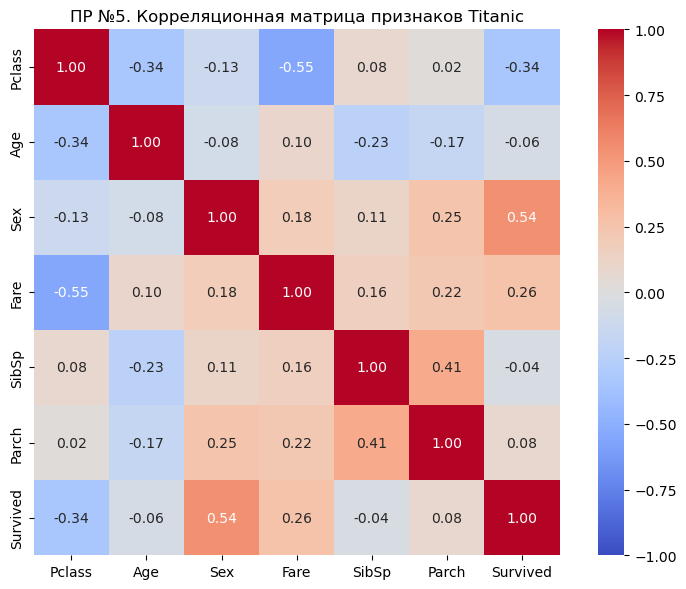

In [15]:
#  ПР №5: корреляционная матрица 
corr_df = X.copy()
corr_df["Survived"] = y

corr_matrix = corr_df.corr(numeric_only=True).round(2)
print(corr_matrix)

# Корреляция с целевой переменной (без самой себя)
surv_corr = corr_matrix["Survived"].drop("Survived").sort_values()
print("\nКорреляция с Survived (по возрастанию):")
print(surv_corr)

# Тепловая карта
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("ПР №5. Корреляционная матрица признаков Titanic")
plt.tight_layout()
plt.show()

In [16]:
#ПР №6: логистическая регрессия
model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train_scaled, y_train)

y_pred_lr = model_lr.predict(X_test_scaled)

print("Первые предсказания:", y_pred_lr[:10])
print("Правильные ответы: ", y_test.iloc[:10].to_list())

print("\n--- Логистическая регрессия ---")
print("Accuracy:",  round(accuracy_score(y_test, y_pred_lr), 4))
print("Precision:", round(precision_score(y_test, y_pred_lr), 4))
print("Recall:   ", round(recall_score(y_test, y_pred_lr), 4))
print("F1:       ", round(f1_score(y_test, y_pred_lr), 4))
print(confusion_matrix(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr, target_names=["не выжил", "выжил"]))

Первые предсказания: [0 0 0 0 1 0 1 0 0 0]
Правильные ответы:  [0, 0, 1, 0, 1, 1, 1, 0, 0, 0]

--- Логистическая регрессия ---
Accuracy: 0.8045
Precision: 0.7656
Recall:    0.7101
F1:        0.7368
[[95 15]
 [20 49]]
              precision    recall  f1-score   support

    не выжил       0.83      0.86      0.84       110
       выжил       0.77      0.71      0.74        69

    accuracy                           0.80       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



In [17]:
#ПР №6: дерево решений 
model_tree = DecisionTreeClassifier(max_depth=4, random_state=42)
model_tree.fit(X_train, y_train)   # масштабирование не нужно
y_pred_tree = model_tree.predict(X_test)

print("--- Дерево решений (max_depth=4) ---")
print("Accuracy:",  round(accuracy_score(y_test, y_pred_tree), 4))
print("Precision:", round(precision_score(y_test, y_pred_tree), 4))
print("Recall:   ", round(recall_score(y_test, y_pred_tree), 4))
print("F1:       ", round(f1_score(y_test, y_pred_tree), 4))
print(confusion_matrix(y_test, y_pred_tree))

# Важность признаков
importance = pd.Series(model_tree.feature_importances_, index=features).sort_values(ascending=False)
print("\nВажность признаков:\n", importance.round(3))

--- Дерево решений (max_depth=4) ---
Accuracy: 0.7821
Precision: 0.875
Recall:    0.5072
F1:        0.6422
[[105   5]
 [ 34  35]]

Важность признаков:
 Sex       0.590
Pclass    0.201
Fare      0.096
Age       0.091
SibSp     0.012
Parch     0.010
dtype: float64
